# Part 1: Text Processing and Exploratory Data Analysis

This notebook contains all the code for Part 1. 

The pre-processing functions are declared in
`preprocessing.py`.

Structure:
1. Setup and loading
2. **Part 1 – Data preparation**: raw data overview, data quality problems, text pre-processing,
   output fields, handling of categorical fields (Q3) and numeric fields (Q4)
3. **Part 2 – Exploratory Data Analysis**
4. Summary of decisions

## 1. Setup and loading

In [12]:
import os, sys, re, json, math
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk

# the notebook lives in project_progress/part_1, the repo root is two levels up
ROOT = os.path.abspath(os.path.join(os.getcwd(), "..", ".."))
sys.path.insert(0, ROOT)
DATA_PATH = os.path.join(ROOT, "data", "fashion_products_dataset.json")
LABELS_PATH = os.path.join(ROOT, "data", "validation_labels.csv")
FIG_DIR = os.path.join(os.getcwd(), "figures")
os.makedirs(FIG_DIR, exist_ok=True)

for res in ["stopwords", "punkt", "punkt_tab"]:
    nltk.download(res, quiet=True)

import preprocessing as pp

"""
sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 200)
"""

def savefig(name):
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, f"{name}.png"), dpi=150, bbox_inches="tight")
    plt.show()

In [13]:
raw = pd.read_json(DATA_PATH)
labels = pd.read_csv(LABELS_PATH)
print("documents:", raw.shape[0], "| columns:", raw.shape[1])
print("validation labels:", labels.shape[0], "rows")
raw.head(3)

documents: 28080 | columns: 17
validation labels: 40 rows


,_id,actual_price,average_rating,brand,category,crawled_at,description,discount,images,out_of_stock,pid,product_details,seller,selling_price,sub_category,title,url
0,fa8e22d6-c0b6-5229-bb9e-ad52eda39a0a,"2,999",3.9,York,Clothing and Accessories,2021-02-10 20:11:51,Yorker trackpants made from 100% rich combed c...,69% off,[https://rukminim1.flixcart.com/image/128/128/...,False,TKPFCZ9EA7H5FYZH,"[{'Style Code': '1005COMBO2'}, {'Closure': 'El...",Shyam Enterprises,921,Bottomwear,Solid Women Multicolor Track Pants,https://www.flipkart.com/yorker-solid-men-mult...
1,893e6980-f2a0-531f-b056-34dd63fe912c,"1,499",3.9,York,Clothing and Accessories,2021-02-10 20:11:52,Yorker trackpants made from 100% rich combed c...,66% off,[https://rukminim1.flixcart.com/image/128/128/...,False,TKPFCZ9EJZV2UVRZ,"[{'Style Code': '1005BLUE'}, {'Closure': 'Draw...",Shyam Enterprises,499,Bottomwear,Solid Men Blue Track Pants,https://www.flipkart.com/yorker-solid-men-blue...
2,eb4c8eab-8206-59d0-bcd1-a724d96bf74f,"2,999",3.9,York,Clothing and Accessories,2021-02-10 20:11:52,Yorker trackpants made from 100% rich combed c...,68% off,[https://rukminim1.flixcart.com/image/128/128/...,False,TKPFCZ9EHFCY5Z4Y,"[{'Style Code': '1005COMBO4'}, {'Closure': 'El...",Shyam Enterprises,931,Bottomwear,Solid Men Multicolor Track Pants,https://www.flipkart.com/yorker-solid-men-mult...


# 2. Part 1 – Data preparation

## 2.1 Raw data overview

Before deciding anything we looked at the fields, their types and how many values are missing.
Note that empty strings (`""`) are used for missing values instead of `null`, so we count both.

In [14]:
def missing(s):
    return s.isna().sum() + (s.astype(str).str.strip() == "").sum()

overview = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "missing": [missing(raw[c]) for c in raw.columns],
})

overview["missing_%"] = (100 * overview["missing"] / len(raw)).round(2)
overview["example"] = [str(raw[c].iloc[0])[:60] for c in raw.columns]
print("duplicated pid:", raw.pid.duplicated().sum())
overview

duplicated pid: 0


,dtype,missing,missing_%,example
_id,object,0,0.00,fa8e22d6-c0b6-5229-bb9e-ad52eda39a0a
actual_price,object,777,2.77,"2,999"
average_rating,object,2261,8.05,3.9
brand,object,2009,7.15,York
category,object,0,0.00,Clothing and Accessories
crawled_at,datetime64[ns],0,0.00,2021-02-10 20:11:51
description,object,11150,39.71,Yorker trackpants made from 100% rich combed c...
discount,object,855,3.04,69% off
images,object,0,0.00,['https://rukminim1.flixcart.com/image/128/128...
out_of_stock,bool,0,0.00,False


Observations:
- `pid` is unique, so we can use it as document id (it is also the id used in `validation_labels.csv`).
- **~40% of the descriptions are empty**. For many products the only text is the title and the
  `product_details`, so we cannot rely on the description alone.
- Prices, discount and rating are stored as **strings** (`"2,999"`, `"69% off"`, `"3.9"`), they must be parsed.
- `product_details` is a list of one-key dictionaries, we convert it into a single dictionary.

## 2.2 Data quality problems we found

While inspecting the data we found several issues that affect retrieval directly.

**(a) Encoding errors.** 6.5% of the non-empty descriptions contain non-ASCII characters (mostly curly
quotes `’` and non-breaking spaces), and a small number contain real *mojibake*: UTF-8 text that was decoded
with the wrong encoding, sometimes twice (e.g. `itÃ\x83Â¢Ã\x82Â\x80Ã\x82Â\x99s` instead of `it's`).
A tokenizer would turn these into garbage tokens or split the word.

In [15]:
desc = raw.description[raw.description.str.len() > 0]
non_ascii = desc.str.contains(r"[^\x00-\x7f]").mean()
print(f"descriptions with non-ASCII characters: {non_ascii:.1%}")
moji = desc[desc.str.contains("â€|Ã")]
print(f"descriptions with mojibake: {len(moji)} ({len(moji)/len(desc):.1%} of non-empty)")
for ex in moji.iloc[[0, 2]]:
    i = re.search("â€|Ã", ex).start()
    snippet = ex[max(0, i - 25):i + 25]
    print("before:", repr(snippet))
    print("after: ", repr(pp.fix_encoding(snippet)))

descriptions with non-ASCII characters: 6.5%
descriptions with mojibake: 43 (0.3% of non-empty)
before: 'r They Deal In Regularly.Ã\x82Â\xa0'
after:  'r They Deal In Regularly.\xa0'
before: 'rbane personality with itÃ\x83Â¢Ã\x82Â\x80Ã\x82Â\x99s classy shir'
after:  "rbane personality with it's classy shir"


**(b) Words glued together.** In ~7% of descriptions the sentences are joined without a space
(`look.Designed`, `Comfort,Skin`) and in some cases even the brand is glued to the next word
(`ECKO UnltdSlim Fit`). A naive tokenizer would create tokens like `look.designed` or `unltdslim`.

In [16]:
print("descriptions with '<letter><punct><Letter>':",
      f"{desc.str.contains(r'[a-z][.,;:][A-Z]').mean():.1%}")
for s in ["rich look.Designed for Comfort,Skin friendly fabric", "ECKO UnltdSlim Fit SINGLE JERSEY Cotton BLACK T-Shirt"]:
    print(f"{s!r:60} -> {pp.normalize_text(s)!r}")

descriptions with '<letter><punct><Letter>': 7.4%
'rich look.Designed for Comfort,Skin friendly fabric'        -> 'rich look. designed for comfort, skin friendly fabric'
'ECKO UnltdSlim Fit SINGLE JERSEY Cotton BLACK T-Shirt'      -> 'ecko unltd slim fit single jersey cotton black tshirt'


**(c) Truncated brand names.** The `brand` field is cut in most products (`Pu`, `REEB`, `ECKO Unl`,
`True Bl`). A user searching for *puma* would never match `pu`. We noticed that the Flipkart URL slug
starts with the full brand name, so we recover it from there (`brand_from_url`).

In [17]:
raw["brand_full"] = [pp.brand_from_url(b, u) for b, u in zip(raw.brand, raw.url)]
nonempty = raw[raw.brand != ""]
norm = lambda s: s.str.lower().str.replace(r"\W", "", regex=True)
changed = norm(nonempty.brand_full).str.len() > norm(nonempty.brand).str.len()
print(f"brands completed using the URL: {changed.sum()} / {len(nonempty)} ({changed.mean():.1%})")
(nonempty[changed][["brand", "brand_full"]].drop_duplicates()
 .merge(nonempty.brand.value_counts().rename("n_products"), left_on="brand", right_index=True)
 .sort_values("n_products", ascending=False).head(10))

brands completed using the URL: 24741 / 26071 (94.9%)


,brand,brand_full,n_products
11280,ECKO Unl,ecko unltd,951
23267,Free Authori,free authority,860
21168,ARBO,arbour,806
1562,REEB,reebok,802
25319,Pu,puma,798
10221,True Bl,true blue,793
26878,Keo,keoti,660
12442,Amp,ample,585
16600,Black Beat,black beatle,548
26374,vims rai,vims raiyo,503


**(d) Gender in the URL does not match the title.** The URL slug also contains the original product
title. We compared the gender word (*men*/*women*) of the title, the URL and the `Ideal For` product
detail:

In [18]:
def gender(text):
    text = str(text).lower()
    if re.search(r"\bwomen\b", text): return "women"
    if re.search(r"\bmen\b", text): return "men"
    return None

slug = raw.url.str.extract(r"flipkart\.com/([^/]+)/p/")[0].fillna("").str.replace("-", " ")
g = pd.DataFrame({
    "title": raw.title.map(gender),
    "url": slug.map(gender),
    "ideal_for": raw.product_details.map(lambda d: gender(pp.details_to_dict(d).get("Ideal For"))),
})
rows = []
for a, b in [("title", "ideal_for"), ("title", "url"), ("url", "ideal_for")]:
    m = g[a].notna() & g[b].notna()
    rows.append({"pair": f"{a} vs {b}", "n": m.sum(), "agreement": round((g[a][m] == g[b][m]).mean(), 3)})
pd.DataFrame(rows)

,pair,n,agreement
0,title vs ideal_for,16433,1.000
1,title vs url,26036,0.502
2,url vs ideal_for,16433,0.498


Title and `Ideal For` agree in 100% of the cases, while the URL agrees only ~50% of the time, which
is what you would get by chance. Our interpretation is that the gender of the products was modified in the
visible fields (title / product details) but not in the URL. In the validation file, all 20
products of query 1 have *Women* in the title but *men* in the URL, and the labels follow the title.

**Decision:** we never index the URL as text. We only use it to recover the full brand name, and we
return it to the user as a link.

## 2.3 Text pre-processing pipeline

The function `pp.preprocess_text(text)` applies the following steps (in this order):

| # | Step | Why |
|---|------|-----|
| 1 | `fix_encoding` (ftfy) | repair mojibake so words are not broken |
| 2 | ASCII folding (`NFKD`) | `’`→`'`, `é`→`e`, removes strange symbols (`•`, `™`) |
| 3 | split glued words | `look.Designed` → `look. Designed`, `UnltdSlim` → `Unltd Slim` |
| 4 | lowercase | *Cotton* = *cotton* |
| 5 | domain normalisation | `women's`/`womens`/`woman` → `women`; `t-shirt`/`t shirt`/`tee` → `tshirt`; `sweat shirt` → `sweatshirt`; typo `regulor` → `regular` |
| 6 | tokenization `[a-z0-9]+` | splits on any non-alphanumeric char, so **punctuation is removed** at the same time |
| 7 | stop-word removal (NLTK English) | very frequent words with no meaning (*the, for, with*) |
| 8 | remove 1-char tokens and product codes | codes such as `1005combo2` mix letters and digits, they are identifiers and add noise |
| 9 | Porter stemming | `sleeves`→`sleev`, `printed`→`print`, `jeans`→`jean` |

Steps 1–3, 5 and 8 are the extra steps (the "anything else you think is needed" part); each one is motivated by a
problem we saw in section 2.2.

Some details we checked:
- The NLTK stop-word list does **not** contain *men*, *women*, *full*, *slim* or *blue*, which are key
  terms in the validation queries, so we can use the standard list. (Some other lists remove *full*.)
- Porter keeps `sleeveless` different from `sleev`, which is good: a sleeveless top is not a full-sleeve one.
- We keep pure numbers (`100` in "100% cotton", sizes like `32`), we only drop mixed codes.
- For tokenization we used a regex instead of `nltk.word_tokenize` because `word_tokenize` keeps
  punctuation as tokens and treats hyphens inconsistently; with the regex the same rule applies to documents and queries.

In [19]:
example = raw[raw.pid == "TKPFCZ9EA7H5FYZH"].iloc[0]
print("TITLE      :", example.title)
print("  ->", pp.preprocess_text(example.title))
print("DESCRIPTION:", example.description)
print("  ->", pp.preprocess_text(example.description))
print()
for q in ["women full sleeve sweatshirt cotton", "men slim jeans blue"]:
    print(f"query {q!r:40} -> {pp.preprocess_text(q)}")

TITLE      : Solid Women Multicolor Track Pants
  -> ['solid', 'women', 'multicolor', 'track', 'pant']
DESCRIPTION: Yorker trackpants made from 100% rich combed cotton giving it a rich look.Designed for Comfort,Skin friendly fabric,itch-free waistband & great for all year round use Proudly made in India
  -> ['yorker', 'trackpant', 'made', '100', 'rich', 'comb', 'cotton', 'give', 'rich', 'look', 'design', 'comfort', 'skin', 'friendli', 'fabric', 'itch', 'free', 'waistband', 'great', 'year', 'round', 'use', 'proudli', 'made', 'india']

query 'women full sleeve sweatshirt cotton'    -> ['women', 'full', 'sleev', 'sweatshirt', 'cotton']
query 'men slim jeans blue'                    -> ['men', 'slim', 'jean', 'blue']


To see the effect of each step, we measured the vocabulary size of the title+description text when
adding the steps one by one (an ablation):

In [20]:
text = (raw.title + " " + raw.description).tolist()

def vocab_size(token_lists):
    return len(set(t for toks in token_lists for t in toks))

steps = {}
steps["whitespace split"] = [t.split() for t in text]
steps["+ lowercase"] = [t.lower().split() for t in text]
steps["+ remove punctuation (regex tokenizer)"] = [re.findall(r"[a-z0-9]+", t.lower()) for t in text]
steps["+ encoding fix, glued words, domain norm."] = [pp.tokenize(pp.normalize_text(pp.fix_encoding(t))) for t in text]
steps["+ stop words, codes, 1-char"] = [pp.preprocess_text(t, stem=False) for t in text]
steps["+ Porter stemming (final)"] = [pp.preprocess_text(t) for t in text]

ablation = pd.DataFrame({
    "vocabulary": {k: vocab_size(v) for k, v in steps.items()},
    "avg tokens / doc": {k: round(np.mean([len(x) for x in v]), 1) for k, v in steps.items()},
})
ablation

,vocabulary,avg tokens / doc
whitespace split,13521,36.2
+ lowercase,10606,36.2
+ remove punctuation (regex tokenizer),6503,37.6
"+ encoding fix, glued words, domain norm.",6432,36.7
"+ stop words, codes, 1-char",6187,25.0
+ Porter stemming (final),4717,25.0


The vocabulary goes from ~13.5k raw "words" to ~4.7k terms (−65%). The biggest drop comes from lowercasing and
removing punctuation (13.5k → 6.5k: many tokens were like `cotton,` or `look.designed`), and stemming merges
singular/plural and verb forms (6.2k → 4.7k). Stop words barely change the vocabulary, but they remove about a third of
the tokens of each document (36.7 → 25.0 tokens on average), which makes the index smaller and the term weights more meaningful.
The encoding/glued-words/normalisation step has a small effect on the vocabulary size (−71 terms), but it fixes
exactly the cases that matter for matching (`women's`, `t-shirt`, `UnltdSlim`).

Now we process the whole corpus. `pp.preprocess_document` keeps the clean typed fields for display
and produces one list of terms per text field plus a merged `all_terms` field.

In [21]:
%%time
corpus = pp.preprocess_corpus(raw)
corpus.to_pickle(os.path.join(ROOT, "data", "processed_corpus.pkl"))
print(corpus.shape)
corpus[["pid", "title_terms", "product_details_terms", "brand_full", "selling_price", "discount", "average_rating"]].head()

(28080, 23)
CPU times: total: 27.8 s
Wall time: 28.4 s


,pid,title_terms,product_details_terms,brand_full,selling_price,discount,average_rating
TKPFCZ9EA7H5FYZH,TKPFCZ9EA7H5FYZH,"[solid, women, multicolor, track, pant]","[elast, side, pocket, cotton, blend, solid, mu...",yorker,921.0,69.0,3.9
TKPFCZ9EJZV2UVRZ,TKPFCZ9EJZV2UVRZ,"[solid, men, blue, track, pant]","[drawstr, elast, side, pocket, cotton, blend, ...",yorker,499.0,66.0,3.9
TKPFCZ9EHFCY5Z4Y,TKPFCZ9EHFCY5Z4Y,"[solid, men, multicolor, track, pant]","[elast, side, pocket, cotton, blend, solid, mu...",yorker,931.0,68.0,3.9
TKPFCZ9ESZZ7YWEF,TKPFCZ9ESZZ7YWEF,"[solid, women, multicolor, track, pant]","[elast, side, pocket, cotton, blend, solid, mu...",yorker,911.0,69.0,3.9
TKPFCZ9EVXKBSUD7,TKPFCZ9EVXKBSUD7,"[solid, women, brown, grey, track, pant]","[drawstr, elast, side, pocket, cotton, blend, ...",yorker,943.0,68.0,3.9


## 2.4 Fields returned for each document

For future queries the search engine must return `pid, title, description, brand, category,
sub_category, product_details, seller, out_of_stock, selling_price, discount, actual_price,
average_rating, url`. The processed corpus keeps all of them **unprocessed** (original text, but with
encoding fixed and numbers parsed), because the processed terms are only for matching and are not readable.
Missing values are returned as `None`, so the interface can show "not available" instead of an empty string or a 0.

In [22]:
def get_output_record(pid):
    # returns the information shown to the user for a retrieved document
    rec = corpus.loc[pid, pp.OUTPUT_FIELDS].to_dict()
    return {k: (None if (isinstance(v, float) and math.isnan(v)) else v) for k, v in rec.items()}

print(json.dumps(get_output_record("TKPFCZ9EA7H5FYZH"), indent=2, default=str))

{
  "pid": "TKPFCZ9EA7H5FYZH",
  "title": "Solid Women Multicolor Track Pants",
  "description": "Yorker trackpants made from 100% rich combed cotton giving it a rich look.Designed for Comfort,Skin friendly fabric,itch-free waistband & great for all year round use Proudly made in India",
  "brand": "York",
  "category": "Clothing and Accessories",
  "sub_category": "Bottomwear",
  "product_details": {
    "Style Code": "1005COMBO2",
    "Closure": "Elastic",
    "Pockets": "Side Pockets",
    "Fabric": "Cotton Blend",
    "Pattern": "Solid",
    "Color": "Multicolor"
  },
  "seller": "Shyam Enterprises",
  "out_of_stock": false,
  "selling_price": 921.0,
  "discount": 69.0,
  "actual_price": 2999.0,
  "average_rating": 3.9,
  "url": "https://www.flipkart.com/yorker-solid-men-multicolor-track-pants/p/itmd2c76aadce459?pid=TKPFCZ9EA7H5FYZH&lid=LSTTKPFCZ9EA7H5FYZHVYXWP0&marketplace=FLIPKART&srno=b_1_1&otracker=browse&fm=organic&iid=177a46eb-d053-4732-b3de-fcad6ff59cbd.TKPFCZ9EA7H5FYZH.SEAR

## 2.5 Q3 – How to handle `category`, `sub_category`, `brand`, `product_details` and `seller`

There are basically three options:

| Option | Pros | Cons |
|---|---|---|
| **A. Merge everything into one text field** | simplest index, any query term matches anywhere, works directly with TF-IDF/cosine | all fields weigh the same, so a match on *cotton* in a washing instruction counts like a match in the title; repeated values (category) inflate document length; we can't filter by brand or seller |
| **B. Separate field-level indices** | each field can get its own weight (e.g. title > details > description), allows field queries and filters (`brand:puma`), statistics such as IDF are computed per field | more complex index and ranking; we need to tune weights; short fields (brand) have very skewed length statistics |
| **C. Structured attributes (not text)** | low-cardinality fields work better as filters/facets than as terms | do not help free-text matching |

To decide, we looked at two things: (1) how distinctive each field is in the corpus, and
(2) whether the field helps separate relevant from non-relevant products in `validation_labels.csv`.

In [23]:
rows = []
for f in ["category", "sub_category", "brand_full", "seller"]:
    s = corpus[f].fillna("")
    vc = s[s != ""].value_counts(normalize=True)
    rows.append({"field": f, "distinct values": s[s != ""].nunique(), "missing %": round(100 * (s == "").mean(), 1),
                 "most common value": vc.index[0], "share of most common %": round(100 * vc.iloc[0], 1),
                 "entropy (bits)": round(-(vc * np.log2(vc)).sum(), 2)})
for f in ["product_details"]:
    rows.append({"field": f, "distinct values": None, "missing %": round(100 * (corpus[f + "_terms"].str.len() == 0).mean(), 1),
                 "most common value": "(key/value list)", "share of most common %": None,
                 "entropy (bits)": None})
pd.DataFrame(rows).set_index("field")

,distinct values,missing %,most common value,share of most common %,entropy (bits)
field,,,,,
category,4.0,0.0,Clothing and Accessories,96.6,0.22
sub_category,24.0,0.0,Topwear,54.5,2.28
brand_full,323.0,7.2,ecko unltd,3.6,6.83
seller,534.0,5.9,RetailNet,5.3,7.13
product_details,NaN,0.3,(key/value list),NaN,NaN


- `category` has only 4 values and 96.6% of the products are *Clothing and Accessories*: as a term it
  has an IDF close to 0, so it adds no ranking information. It is only useful as a **filter**.
- `sub_category` is a bit better (24 values) but still very general (*Topwear*, *Bottomwear*).
- `brand` and `seller` are very distinctive (high entropy), but people rarely type the seller name.
  The brand, on the other hand, is a typical query term (*puma t-shirt*).
- `product_details` contains exactly the attributes users search for: *Sleeve: Full Sleeve*,
  *Fabric: Cotton*, *Fit: Slim*, *Color: Blue*, *Ideal For: Women*:

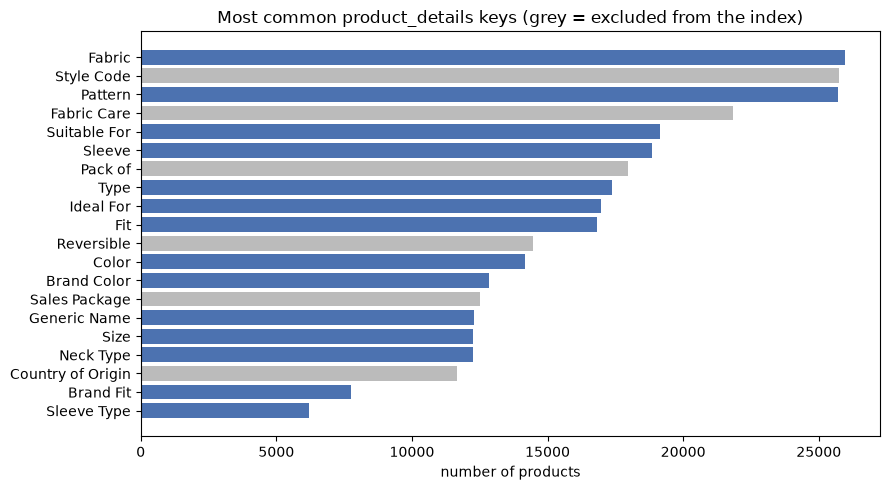

Sleeve     [('Half Sleeve', 7506), ('Full Sleeve', 6372), ('Short Sleeve', 3585), ('Sleeveless', 988), ('3/4th Sleeve', 233)]
Fit        [('Regular', 11835), ('Slim', 3831), ('Slim Fit', 572), ('Regular Fit', 290), ('Tailored', 32)]
Fabric     [('Cotton Blend', 10635), ('Pure Cotton', 4954), ('Polycotton', 2667), ('Polyester', 1246), ('Denim', 561)]
Ideal For  [('Women', 8501), ('Men', 8448), ('Women, Girls', 13), ('Men, Boys', 11), ('Boys, Men', 4)]
Color      [('Multicolor', 2528), ('Blue', 2172), ('Black', 1951), ('Grey', 1247), ('Dark Blue', 757)]


In [24]:
detail_keys = Counter(k for d in corpus.product_details for k in d)
top_keys = pd.Series(detail_keys).sort_values(ascending=False).head(20)
excluded = [k for k in top_keys.index if k in pp.EXCLUDED_DETAIL_KEYS]
plt.figure(figsize=(9, 5))
colors = ["#bbbbbb" if k in pp.EXCLUDED_DETAIL_KEYS else "#4c72b0" for k in top_keys.index]
plt.barh(top_keys.index[::-1], top_keys.values[::-1], color=colors[::-1])
plt.xlabel("number of products")
plt.title("Most common product_details keys (grey = excluded from the index)")
savefig("product_details_keys")
for k in ["Sleeve", "Fit", "Fabric", "Ideal For", "Color"]:
    vals = Counter(d[k] for d in corpus.product_details if k in d).most_common(5)
    print(f"{k:10}", vals)

From `product_details` we index **only the values** (not the keys, since *Fabric* or *Pattern* appear in almost
every product and would be useless terms), and we exclude keys that do not describe the product:
`Style Code` (an identifier), `Fabric Care` (*"machine wash as per tag"*), `Sales Package`,
`Country of Origin` (almost always *India*), `Pack of`, `Reversible`, `Number of Contents in Sales Package`.

**Validation evidence.** For each validation product we computed the fraction of query terms that
appear in each field, separately for relevant and non-relevant products:

In [25]:
QUERIES = {1: "women full sleeve sweatshirt cotton", 2: "men slim jeans blue"}
fields = pp.TEXT_FIELDS + ["all"]
rows = []
for qid, qtext in QUERIES.items():
    qterms = set(pp.preprocess_text(qtext))
    sub = labels[labels.query_id == qid]
    for f in fields:
        cov = sub.pid.map(lambda p: len(qterms & set(corpus.loc[p, f + "_terms"])) / len(qterms))
        rows.append({"query": qid, "field": f,
                     "relevant": cov[sub.labels == 1].mean(), "non-relevant": cov[sub.labels == 0].mean()})
coverage = pd.DataFrame(rows)
coverage["difference"] = coverage["relevant"] - coverage["non-relevant"]
coverage.pivot(index="field", columns="query", values=["relevant", "non-relevant", "difference"]).round(2).loc[fields]

relevant       non-relevant       difference      
query                  1     2            1     2          1     2
field                                                             
title               0.80  0.80         0.46  0.72       0.34  0.08
description         0.58  0.35         0.63  0.42      -0.04 -0.08
brand               0.00  0.00         0.00  0.00       0.00  0.00
category            0.00  0.00         0.00  0.00       0.00  0.00
sub_category        0.00  0.00         0.00  0.00       0.00  0.00
product_details     0.71  0.62         0.57  0.45       0.14  0.18
seller              0.00  0.00         0.00  0.00       0.00  0.00
all                 1.00  0.90         1.00  0.80       0.00  0.10

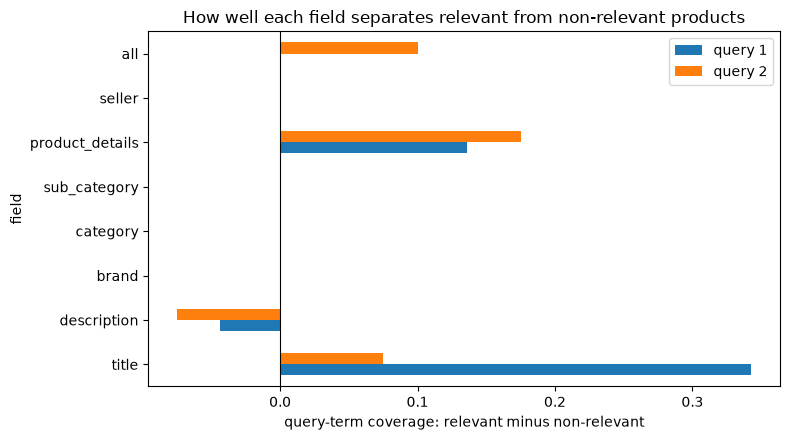

In [26]:
cov_plot = coverage.pivot(index="field", columns="query", values="difference").loc[fields]
cov_plot.columns = [f"query {c}" for c in cov_plot.columns]
cov_plot.plot.barh(figsize=(8, 4.5))
plt.axvline(0, color="black", lw=0.8)
plt.xlabel("query-term coverage: relevant minus non-relevant")
plt.title("How well each field separates relevant from non-relevant products")
savefig("field_separation_validation")

This was the most useful result for our decision:
- With **one merged field**, for query 1 *all* the candidates (relevant and not) contain the 5 query terms
  somewhere, so the coverage is 1.00 vs 1.00 and the merged field cannot separate them.
- The **title** separates best (+0.34 for query 1): the non-relevant products are mostly T-shirts that mention
  *sweatshirt*/*cotton* only in the description or details.
- **product_details** also helps (+0.14 / +0.18): the `Sleeve` value (*Full* vs *Half Sleeve*) separates all the
  T-shirts of query 1, and `Fabric` explains one of the three full-sleeve sweatshirts labelled 0 (the Reebok one is
  *Polyester Blend*, not cotton).
- The **description** is slightly *negative*: long descriptions mention many words.
- `brand`, `category`, `sub_category` and `seller` never contain the query terms of these two queries.

**Our decision (hybrid of A, B and C):**
1. Keep **separate term lists per field** (`title`, `description`, `product_details`, `brand`,
   `sub_category`, `category`, `seller`) so that in Part 3 we can weight them (title > product details >
   brand > description) or use a field-weighted model such as BM25F.
2. Also build a **merged field** `all_terms` = title + description + brand + sub_category + product_details,
   which we will use for the basic TF-IDF index of Part 2 (simple and with good recall).
   `category` and `seller` are **not** merged: category has no discriminative power and seller names
   are noise for product queries (e.g. *RetailNet*, *SandSMarketing*).
3. Keep `category`, `sub_category`, `brand` and `seller` also as **raw structured values** to be used as filters/facets.

A note on the labels: they are partly inconsistent. Products with the same title and brand get different labels
(*Full Sleeve Printed Women Sweatshirt* by Puma: 1, 1, 0 in query 1; *Tapered Fit Men Blue Jeans* by ECKO: 0, 1, 1 in query 2),
the other two Puma sweatshirts labelled 0 are cotton blend and look just like the relevant ones, and three *Women* jeans are
labelled relevant for *men slim jeans blue*. So no text-only ranking can reproduce the labels perfectly, and we have to
keep this in mind when we evaluate in Part 2 (the table below and section 3.6 show the details).

In [27]:
v = labels.merge(corpus[["pid", "brand_full", "out_of_stock", "average_rating"]], on="pid")
v["sleeve"] = v.pid.map(lambda p: corpus.loc[p, "product_details"].get("Sleeve"))
v["fabric"] = v.pid.map(lambda p: corpus.loc[p, "product_details"].get("Fabric"))
v.sort_values(["query_id", "labels"])

,title,pid,query_id,labels,brand_full,out_of_stock,average_rating,sleeve,fabric
1,Full Sleeve Striped Women Sweatshirt,SWSFJY5ZFHQ7HXKW,1,0,reebok,False,4.0,Full Sleeve,Polyester Blend
4,Full Sleeve Solid Women Sweatshirt,JCKFTZBC3DMCVYXH,1,0,puma,False,3.7,Full Sleeve,Cotton Blend
6,Typography Women V Neck Multicolor T-Shirt (P...,TSHFUH9FABXHSDPJ,1,0,free authority,False,3.9,Half Sleeve,Pure Cotton
11,Typography Women V Neck Multicolor T-Shirt (P...,TSHFUH9HG5ZHC6FS,1,0,free authority,False,3.9,Half Sleeve,Pure Cotton
12,Full Sleeve Printed Women Sweatshirt,SWSFUY89CJ9WZYQC,1,0,puma,False,4.3,Full Sleeve,Cotton Blend
13,Printed Women V Neck Multicolor T-Shirt (Pack...,TSHFUH9PKWETBZZB,1,0,free authority,False,3.9,Half Sleeve,Pure Cotton
19,Superhero Women Round Neck Multicolor T-Shirt ...,TSHFY24T4KGF2NYU,1,0,free authority,False,3.9,Half Sleeve,Pure Cotton
0,Full Sleeve Printed Women Sweatshirt,SWSFFVKBCQG5FHPF,1,1,cupidstore,False,3.2,Full Sleeve,Cotton Blend
2,Full Sleeve Printed Women Sweatshirt,SWSFUY89NHMZHZPX,1,1,puma,False,4.3,Full Sleeve,Cotton Blend
3,Full Sleeve Graphic Print Women Sweatshirt,SWSFXQ5YX6RZKHP4,1,1,free authority,False,3.9,Full Sleeve,Polycotton


## 2.6 Q4 – Numeric fields: `out_of_stock`, `selling_price`, `discount`, `actual_price`, `average_rating`

**Decision: they are not indexed as textual terms.** We parse them into numbers / booleans and store them as
document attributes. Reasons:
- As text, `921` and `920` would be two unrelated terms. Here, the important property of a number is its
  **order and distance** (cheaper than, rating above), which an inverted index of terms cannot express.
- Users don't type prices to match them exactly. They ask for *"under 500"* or *"best rated"*.
- Number tokens would add thousands of useless terms to the vocabulary.

Parsing rules (`pp.parse_price`, `pp.parse_discount`, `pp.parse_rating`):
- `"2,999"` → `2999.0`; `"69% off"` → `69.0`; `"3.9"` → `3.9`; `out_of_stock` → bool.
- **Missing values stay `None`/NaN, never 0.** A product without a rating is *unrated*, not rated 0, and
  a missing price is not free. Using 0 would make these products look like the worst/cheapest ones.
- If the discount is missing but both prices exist, we compute it as `(actual − selling) / actual`.
  When there is no discount and no actual price, the product is sold at its selling price, so `actual_price = selling_price`.

We also checked that the fields are consistent with each other:

In [28]:
num = corpus[["selling_price", "actual_price", "discount", "average_rating", "out_of_stock"]]
print(num.describe().round(2).to_string())
print()
print("missing values after parsing:")
print(num.isna().sum().to_string())
both = num.dropna(subset=["selling_price", "actual_price", "discount"])
computed = 100 * (both.actual_price - both.selling_price) / both.actual_price
print(f"\n|stated discount - computed discount| <= 1 point: {((both.discount - computed).abs() <= 1).mean():.1%}")
print("products with selling_price > actual_price:", (both.selling_price > both.actual_price).sum())

       selling_price  actual_price  discount  average_rating
count       28078.00      27303.00  27303.00        25819.00
mean          705.64       1455.53     50.11            3.63
std           549.68        939.98     17.07            0.66
min            99.00        150.00      0.00            1.00
25%           390.00        849.00     40.00            3.20
50%           545.00       1199.00     52.00            3.80
75%           820.00       1799.00     63.00            4.10
max          7999.00      12999.00     87.00            5.00

missing values after parsing:
selling_price        2
actual_price       777
discount           777
average_rating    2261
out_of_stock         0

|stated discount - computed discount| <= 1 point: 100.0%
products with selling_price > actual_price: 0


The stated discount matches the one computed from the prices for practically all products, so the fields
are consistent. For future search we plan to use them as:
- `out_of_stock` → filter (or a penalty in the ranking), since normally you don't want to buy something unavailable;
- `selling_price` → range filter (*under X*) and sorting;
- `discount`, `average_rating` → ranking signals combined with the text score in Part 3 (we will need to deal
  with unrated products, e.g. with a neutral prior instead of 0).

# 3. Part 2 – Exploratory Data Analysis

## 3.1 Text statistics: lengths, sentences and vocabulary

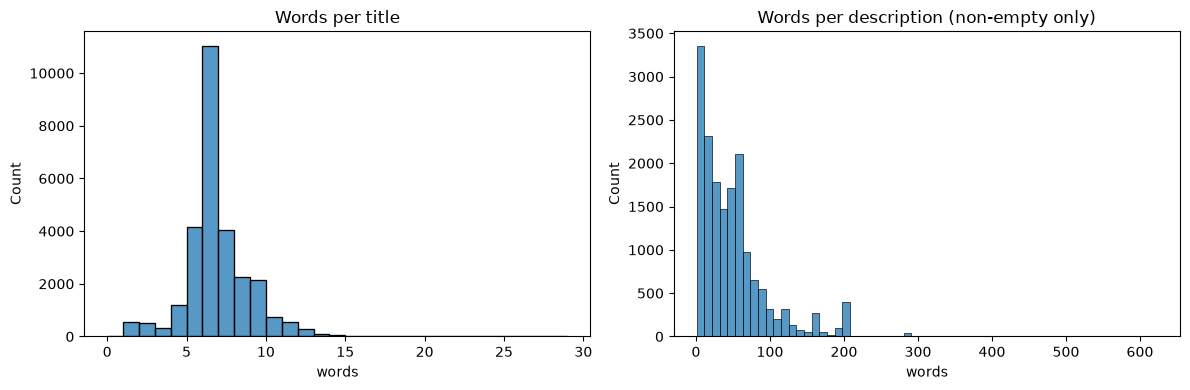

title: mean 6.5, median 6 words
description: 39.7% empty; non-empty mean 49.4, median 39, max 623


In [29]:
title_len = raw.title.str.split().str.len()
desc_len = raw.description.str.split().str.len()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(title_len, bins=range(0, 30), ax=axes[0])
axes[0].set(title="Words per title", xlabel="words")
sns.histplot(desc_len[desc_len > 0], bins=60, ax=axes[1])
axes[1].set(title="Words per description (non-empty only)", xlabel="words")
savefig("length_distributions")
print(f"title: mean {title_len.mean():.1f}, median {title_len.median():.0f} words")
print(f"description: {(desc_len == 0).mean():.1%} empty; non-empty mean {desc_len[desc_len>0].mean():.1f}, median {desc_len[desc_len>0].median():.0f}, max {desc_len.max()}")

In [30]:
def sentences(text):
    # fix encoding and glued sentences first, otherwise "look.Designed" counts as one sentence
    text = pp.fix_encoding(text)
    text = re.sub(r"([a-z])([.!?])([A-Z])", r"\1\2 \3", text)
    return nltk.sent_tokenize(text)

sents = [s for d in desc for s in sentences(d)]
sent_len = pd.Series([len(s.split()) for s in sents])
sents_per_desc = pd.Series([len(sentences(d)) for d in desc])
print(f"sentences in non-empty descriptions: {len(sents)}")
print(f"average sentence length: {sent_len.mean():.1f} words (median {sent_len.median():.0f})")
print(f"average sentences per description: {sents_per_desc.mean():.1f}")

sentences in non-empty descriptions: 54672
average sentence length: 15.3 words (median 14)
average sentences per description: 3.2


In [31]:
all_terms = [t for toks in corpus.all_terms for t in toks]
freq = Counter(all_terms)
print("total terms (after pre-processing):", len(all_terms))
print("vocabulary size:", len(freq))
print("terms that appear only once (hapax):", sum(1 for c in freq.values() if c == 1))
for f in pp.TEXT_FIELDS:
    col = corpus[f + "_terms"]
    print(f"  {f:16} vocabulary {len(set(t for l in col for t in l)):5d}   avg terms/doc {col.str.len().mean():5.1f}")

total terms (after pre-processing): 1256332
vocabulary size: 5865
terms that appear only once (hapax): 1216
  title            vocabulary   716   avg terms/doc   6.3
  description      vocabulary  4528   avg terms/doc  18.8
  brand            vocabulary   407   avg terms/doc   1.3
  category         vocabulary     7   avg terms/doc   2.0
  sub_category     vocabulary    39   avg terms/doc   1.4
  product_details  vocabulary  2960   avg terms/doc  17.0
  seller           vocabulary   648   avg terms/doc   1.7


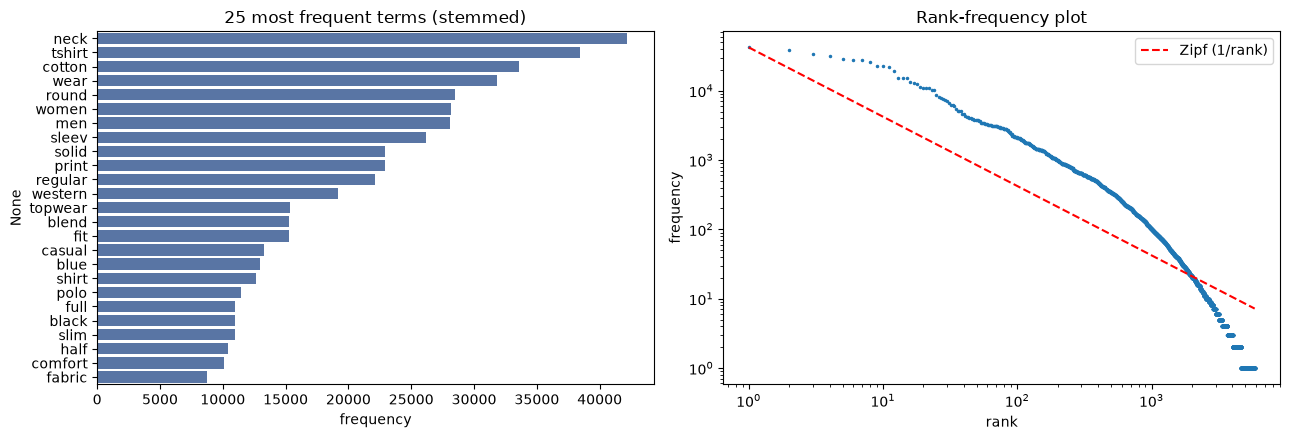

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
top = pd.Series(dict(freq.most_common(25)))
sns.barplot(x=top.values, y=top.index, ax=axes[0], color="#4c72b0")
axes[0].set(title="25 most frequent terms (stemmed)", xlabel="frequency")
ranks = np.arange(1, len(freq) + 1)
counts = np.array(sorted(freq.values(), reverse=True))
axes[1].loglog(ranks, counts, marker=".", linestyle="none", markersize=3)
axes[1].loglog(ranks, counts[0] / ranks, "r--", label="Zipf (1/rank)")
axes[1].set(title="Rank-frequency plot", xlabel="rank", ylabel="frequency")
axes[1].legend()
savefig("term_frequencies_zipf")

The rank-frequency plot follows Zipf's law reasonably well in the middle ranks, with the usual drop in the long
tail (1,216 terms appear only once). The most frequent terms (*neck*, *tshirt*, *cotton*, *wear*, *round*, *women*, *men*,
*sleev*...) come largely from `product_details` (e.g. `Suitable For: Western Wear` appears in 19k products, which is why *western*
is in the top 15). These terms appear in a big part of the collection, so their IDF will be low. This matters for the
validation queries: *cotton* appears in 71% of the documents and *sleev* in 64%, so they will barely help to rank,
and *sweatshirt* (5%) and *jean* (9%) will do most of the work.

## 3.2 Word clouds

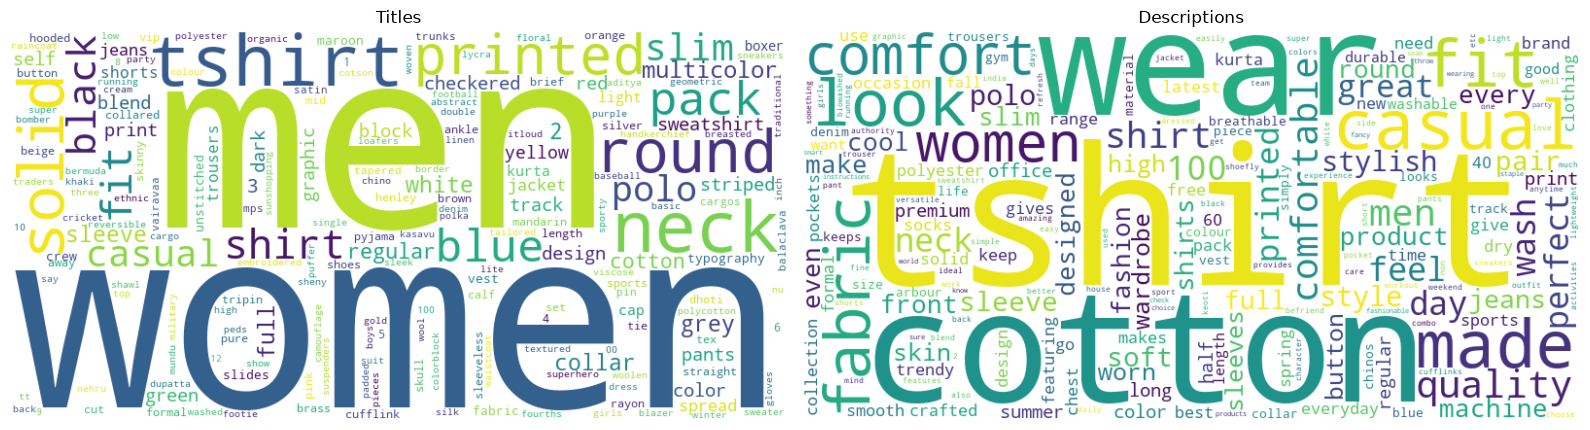

In [33]:
from wordcloud import WordCloud

def plot_wordcloud(token_lists, title, ax):
    wc = WordCloud(width=800, height=400, background_color="white", random_state=0)
    wc.generate_from_frequencies(Counter(t for toks in token_lists for t in toks))
    ax.imshow(wc, interpolation="bilinear")
    ax.set_title(title)
    ax.axis("off")

# without stemming, so the words are readable
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
plot_wordcloud([pp.preprocess_text(t, stem=False) for t in raw.title], "Titles", axes[0])
plot_wordcloud([pp.preprocess_text(t, stem=False) for t in desc], "Descriptions", axes[1])
savefig("wordclouds")

For the word clouds we used the pipeline without stemming so that the words are readable. Titles are
dominated by gender and product type (*women*, *men*, *tshirt*, *neck*, *round*, *printed*, *solid*), while
descriptions contain more marketing vocabulary (*wear*, *casual*, *look*, *comfort*, *quality*, *perfect*, *stylish*).
This is another reason to give more weight to the title than to the description.

## 3.3 Categories, brands and sellers

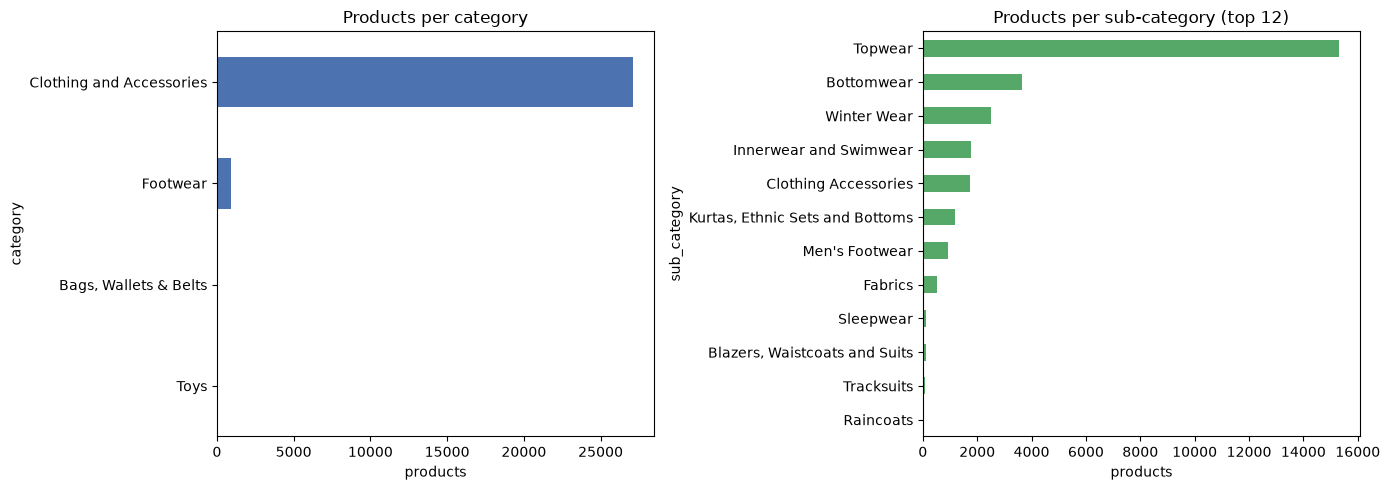

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
raw.category.value_counts().plot.barh(ax=axes[0], color="#4c72b0")
axes[0].set(title="Products per category", xlabel="products")
axes[0].invert_yaxis()
raw.sub_category.value_counts().head(12).plot.barh(ax=axes[1], color="#55a868")
axes[1].set(title="Products per sub-category (top 12)", xlabel="products")
axes[1].invert_yaxis()
savefig("categories")

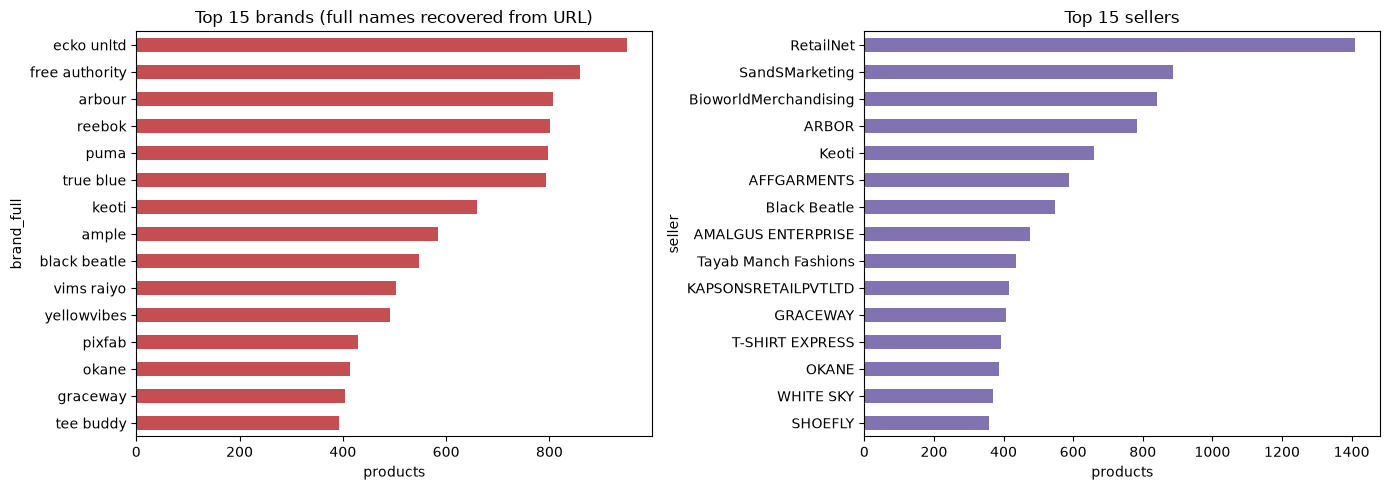

distinct brands: 323 | distinct sellers: 534


In [35]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
corpus.brand_full.value_counts().head(15).plot.barh(ax=axes[0], color="#c44e52")
axes[0].set(title="Top 15 brands (full names recovered from URL)", xlabel="products")
axes[0].invert_yaxis()
raw.seller[raw.seller != ""].value_counts().head(15).plot.barh(ax=axes[1], color="#8172b2")
axes[1].set(title="Top 15 sellers", xlabel="products")
axes[1].invert_yaxis()
savefig("top_brands_sellers")
print("distinct brands:", corpus.brand_full.nunique(), "| distinct sellers:", raw.seller[raw.seller != ''].nunique())

In [36]:
# brands and sellers with the best average rating (only those with at least 50 rated products, to avoid noise)
def ranking_by(col, min_products=50):
    g = corpus.dropna(subset=["average_rating"]).groupby(col)
    t = g.agg(products=("pid", "count"), avg_rating=("average_rating", "mean"),
              avg_price=("selling_price", "mean"), avg_discount=("discount", "mean"))
    return t[t.products >= min_products].sort_values("avg_rating", ascending=False).round(2)

print("Top brands by average rating:")
display(ranking_by("brand_full").head(10))
print("Top sellers by average rating:")
display(ranking_by("seller").head(10))

Top brands by average rating:


,products,avg_rating,avg_price,avg_discount
brand_full,,,,
sorang,74,4.61,694.19,61.50
pixfab,328,4.46,303.27,76.07
cotson,277,4.44,356.88,39.19
zack ford,128,4.33,571.20,62.27
u s polo assn,50,4.32,1555.80,41.96
oneiro,57,4.23,520.74,62.67
graceway,404,4.23,412.48,58.42
marca disati,334,4.19,583.29,43.40
reebok classics,75,4.14,1723.51,44.85


Top sellers by average rating:


,products,avg_rating,avg_price,avg_discount
seller,,,,
SORANG,74,4.61,694.19,61.50
EVINCEMARKETERS,320,4.48,357.75,38.84
PixFab,309,4.46,303.81,76.04
KrishnamEnterprisaes,128,4.33,571.20,62.27
GRACEWAY,408,4.23,415.41,58.19
Marca Disati,330,4.20,581.61,43.36
VAIRAVAA TEX,138,4.17,1450.12,38.01
Assiduus Distribution,90,4.17,921.99,35.00
RetailNet,1411,4.11,1500.13,43.05


## 3.4 Stock, prices, discounts and ratings

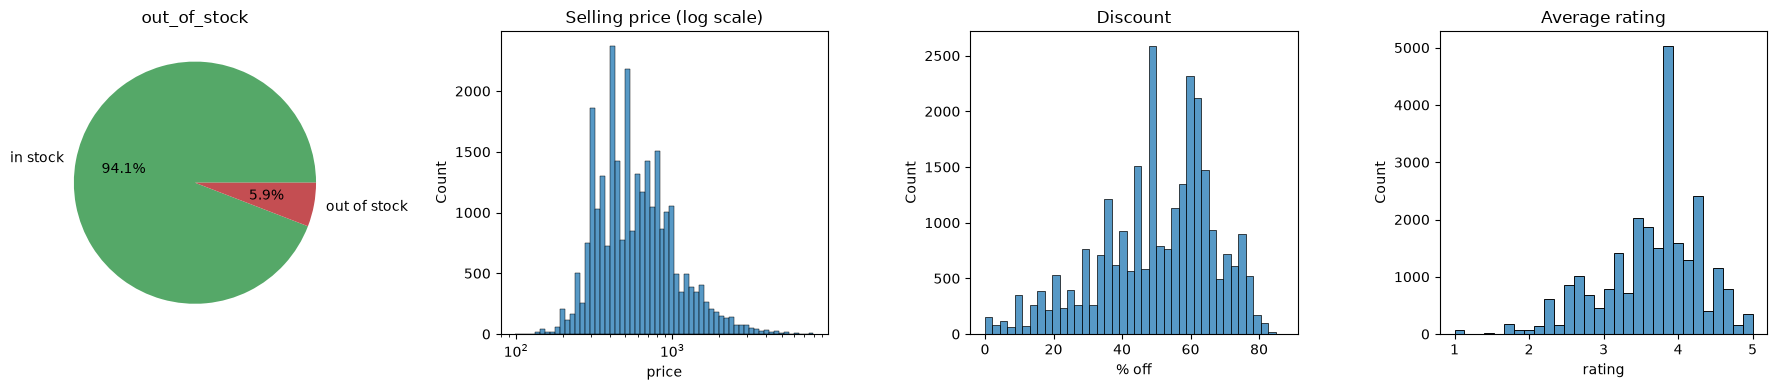

selling_price      545.0
actual_price      1199.0
discount            52.0
average_rating       3.8
Name: median, dtype: float64


In [37]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
oos = raw.out_of_stock.value_counts()
axes[0].pie(oos.values, labels=["in stock", "out of stock"], autopct="%1.1f%%", colors=["#55a868", "#c44e52"])
axes[0].set_title("out_of_stock")
sns.histplot(corpus.selling_price.dropna(), bins=60, log_scale=True, ax=axes[1])
axes[1].set(title="Selling price (log scale)", xlabel="price")
sns.histplot(corpus.discount.dropna(), bins=40, ax=axes[2])
axes[2].set(title="Discount", xlabel="% off")
sns.histplot(corpus.average_rating.dropna(), bins=30, ax=axes[3])
axes[3].set(title="Average rating", xlabel="rating")
savefig("numeric_distributions")
print(corpus[["selling_price", "actual_price", "discount", "average_rating"]].median().rename("median"))

In [38]:
cols = ["title", "brand_full", "selling_price", "actual_price", "discount", "average_rating", "out_of_stock"]
print("Highest rated products:")
display(corpus.sort_values(["average_rating", "discount"], ascending=False)[cols].head(10))
print("Highest discounts:")
display(corpus.sort_values("discount", ascending=False)[cols].head(10))
print("Most expensive products:")
display(corpus.sort_values("selling_price", ascending=False)[cols].head(10))
print("number of products with rating 5.0:", (corpus.average_rating == 5).sum())

Highest rated products:


,title,brand_full,selling_price,actual_price,discount,average_rating,out_of_stock
KTAFAKGUKA2SXSEQ,Men Solid Cotton Blend Pathani Kurta (Blue),purple state,449.0,2599.0,82.0,5.0,False
BXRFKYKYF3SGUMFH,Printed Men Boxer (Pack of 1),sayitloud,249.0,1149.0,78.0,5.0,False
TSHFNJ9ZEUZG3CPU,Printed Women Round Neck Multicolor T-Shirt,yellowvibes,275.0,1200.0,77.0,5.0,False
TSHFU5AF8KZC5FYH,Printed Women Round Neck Black T-Shirt,pixfab,289.0,1299.0,77.0,5.0,False
TSHFTT2JATXKUHEV,Solid Women Round Neck Black T-Shirt,pixfab,288.0,1299.0,77.0,5.0,True
TSHFSPXRXEFVFTXG,Solid Women Round Neck Dark Blue T-Shirt,pixfab,288.0,1299.0,77.0,5.0,True
TSHFTT2STQWNBH23,Printed Men Round Neck Blue T-Shirt,pixfab,288.0,1299.0,77.0,5.0,True
TSHFTT2JUVYZFJZY,Solid Women Round Neck Yellow T-Shirt,pixfab,288.0,1299.0,77.0,5.0,False
TSHFTT2SFXUT3N7F,Printed Women Round Neck Yellow T-Shirt,pixfab,288.0,1299.0,77.0,5.0,False
TSHFTT2SZVYFXHJV,Printed Women Round Neck Red T-Shirt,pixfab,288.0,1299.0,77.0,5.0,True


Highest discounts:


,title,brand_full,selling_price,actual_price,discount,average_rating,out_of_stock
TSHF5FRXKGF6A4FH,Printed Women Round Neck White T-Shirt,jack royal,128.0,998.0,87.0,3.0,False
TSHFMFXGFJ7G2ABK,Printed Women Round Neck Grey T-Shirt,jack royal,136.0,999.0,86.0,4.1,True
TSHFMFT7VASAHBH3,Printed Women Round Neck White T-Shirt,jack royal,136.0,999.0,86.0,4.7,False
TSHFGH6T3CVGDXS9,Printed Men Round Neck Multicolor T-Shirt (Pa...,yellowvibes,449.0,2999.0,85.0,3.2,False
CAPE9YWMURE4FKAJ,Solid Balclava Cap,graceway,228.0,1499.0,84.0,4.3,False
TSHFGFNBYVKZBQ2M,Printed Men Collared Neck Multicolor T-Shirt,yellowvibes,230.0,1500.0,84.0,4.6,False
TSHEYQ73AFZZ4QHX,"Printed Women Round or Crew Black, Grey T-Shirt",fairdeals,201.0,1299.0,84.0,3.8,False
TSHFHQNCHJJUQYVQ,Printed Women Round Neck Blue T-Shirt,yellowvibes,280.0,1800.0,84.0,3.4,False
TSHFKHRYJYMEMZHK,Printed Men Mandarin Collar Blue T-Shirt,yellowvibes,282.0,1800.0,84.0,4.2,False
CAPE9YWMSVSZPM2K,Solid Balclava Cap,graceway,228.0,1499.0,84.0,4.3,False


Most expensive products:


,title,brand_full,selling_price,actual_price,discount,average_rating,out_of_stock
TKTFZ3YGGMMNBYEZ,Solid Women Track Suit,reebok,7999.0,9999.0,20.0,2.7,True
BZRFVAX2QGTEGHRH,Checkered Single Breasted Party Women Full Sle...,true blue,7998.0,7999.0,0.0,2.6,False
JCKFQF5KMJJ349H8,Full Sleeve Solid Women Casual Jacket,puma,7799.0,12999.0,40.0,3.7,False
SWSFUMFGQFKVZGYH,Full Sleeve Printed Men Sweatshirt,puma,7799.0,12999.0,40.0,4.5,False
JEAF8S4GWU5YKQTF,Skinny Men Blue Jeans,gas,7794.0,12990.0,40.0,4.2,False
BZRFVDGUJHTQHDAX,Self Design Single Breasted Party Women Full S...,true blue,6998.0,6999.0,0.0,2.6,False
JEAF8S4GE8PKH7H3,Regular Fit Men Dark Blue Cotton Blend Trousers,gas,6925.0,10990.0,36.0,4.5,False
JEAF65G3MZYG3BQM,Maxx Regular Men Black Jeans,gas,6692.0,10990.0,39.0,3.8,False
JCKFQF5K72AT2JDC,Full Sleeve Solid Women Casual Jacket,puma,6499.0,12999.0,50.0,3.7,False
JEAFEN3WGHH3ZEFY,Skinny Men Blue Jeans,gas,6493.0,9990.0,35.0,NaN,True


number of products with rating 5.0: 329


329 products have a perfect rating of 5.0 (and 2,437 have ≥ 4.5), several of them out of stock. We don't have
the number of reviews, so a 5.0 is probably based on very few ratings, and ranking only by rating would push these
products to the top.

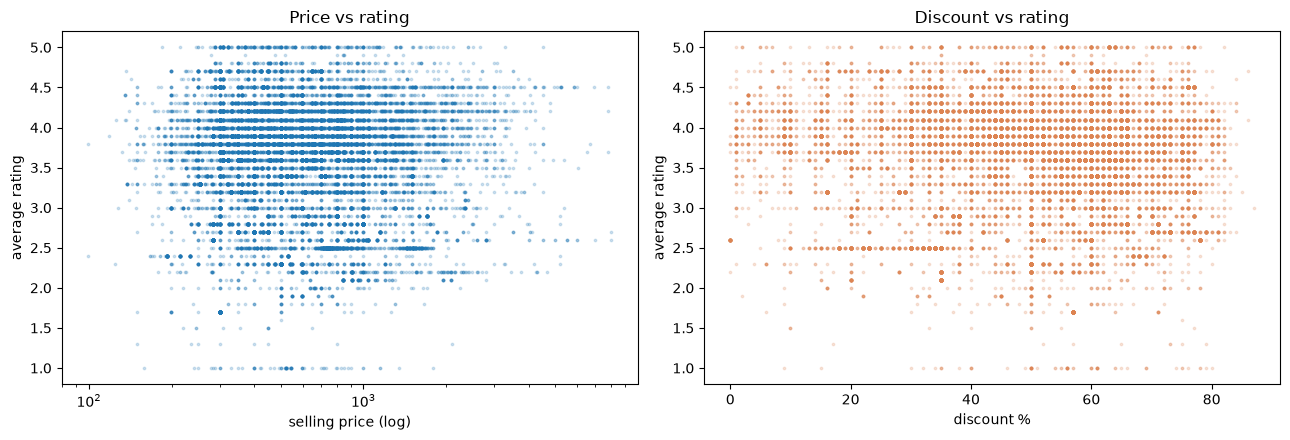

                selling_price  actual_price  discount  average_rating
selling_price            1.00          0.77     -0.35           -0.03
actual_price             0.77          1.00      0.28           -0.09
discount                -0.35          0.28      1.00           -0.09
average_rating          -0.03         -0.09     -0.09            1.00


In [39]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sample = corpus.dropna(subset=["selling_price", "average_rating", "discount"])
axes[0].scatter(sample.selling_price, sample.average_rating, s=3, alpha=0.2)
axes[0].set(xscale="log", xlabel="selling price (log)", ylabel="average rating", title="Price vs rating")
axes[1].scatter(sample.discount, sample.average_rating, s=3, alpha=0.2, color="#dd8452")
axes[1].set(xlabel="discount %", ylabel="average rating", title="Discount vs rating")
savefig("price_discount_vs_rating")
print(sample[["selling_price", "actual_price", "discount", "average_rating"]].corr(method="spearman").round(2))

In [40]:
by_sub = corpus.groupby("sub_category").agg(products=("pid", "count"),
                                            out_of_stock_rate=("out_of_stock", "mean"),
                                            median_price=("selling_price", "median"),
                                            median_discount=("discount", "median"),
                                            mean_rating=("average_rating", "mean"))
by_sub.sort_values("products", ascending=False).head(10).round(2)

,products,out_of_stock_rate,median_price,median_discount,mean_rating
sub_category,,,,,
Topwear,15310,0.04,499.0,53.0,3.59
Bottomwear,3666,0.07,849.0,49.0,3.63
Winter Wear,2493,0.10,949.0,50.0,3.65
Innerwear and Swimwear,1762,0.05,400.0,40.0,3.52
Clothing Accessories,1742,0.17,399.0,57.0,3.95
"Kurtas, Ethnic Sets and Bottoms",1180,0.02,699.0,48.0,3.73
Men's Footwear,920,0.01,320.0,63.0,3.88
Fabrics,534,0.00,379.0,64.0,3.29
Sleepwear,122,0.09,599.0,47.0,3.67


## 3.5 The validation set

In [44]:
print(labels.groupby("query_id").labels.agg(total="count", relevant="sum"))
vv = labels.merge(corpus[["pid", "sub_category", "out_of_stock", "average_rating", "selling_price"]], on="pid")
display(vv.groupby(["query_id", "labels"]).agg(n=("pid", "count"), out_of_stock=("out_of_stock", "sum"),
                                               mean_rating=("average_rating", "mean"),
                                               mean_price=("selling_price", "mean")).round(2))
dups = labels.merge(raw[["pid", "brand"]], on="pid").groupby(["query_id", "title", "brand"]).labels.agg(list)
print("same title+brand with different labels:")
print(dups[dups.map(lambda l: len(set(l)) > 1)])

          total  relevant
query_id                 
1            20        13
2            20        10


n  out_of_stock  mean_rating  mean_price
query_id labels                                           
1        0        7             0         3.94     1392.86
         1       13             2         3.77     1143.08
2        0       10             2         3.36     1959.50
         1       10             1         2.89     1999.60

same title+brand with different labels:
query_id  title                                 brand   
1         Full Sleeve Printed Women Sweatshirt  Pu             [1, 1, 0]
2         Super Skinny Women Blue Jeans         ECKO Unl    [0, 1, 0, 1]
          Tapered Fit Men Blue Jeans            ECKO Unl       [0, 1, 1]
Name: labels, dtype: object


# 4. Summary of decisions

1. **Pre-processing**: encoding repair → ASCII folding → split glued words → lowercase → domain normalisation
   (gender possessives, t-shirt variants, typos) → regex tokenization (removes punctuation) → stop words →
   remove codes and 1-char tokens → Porter stemming. The same function is used for queries.
2. **Output fields**: all 14 required fields are kept in clean, typed form; missing values are `None`.
3. **Categorical fields (Q3)**: hybrid. There is one term list per field,
   a merged `all_terms` field (title, description, brand, sub_category, product_details) for the basic index, and raw values kept
   for filters. `category` and `seller` are left out of the merged field. In `product_details` we index the values only, without non-descriptive keys.
   Brands are completed using the URL.
4. **Numeric fields (Q4)**: parsed to numbers/booleans, not indexed as text; used later as filters and ranking
   signals. Missing values are kept as missing, not 0.
5. **URL**: never indexed as text (its gender words contradict the title in ~50% of products).

The processed corpus is saved to `data/processed_corpus.pkl`.